# SPEIS CSV: plots and data overview

This notebook reads the existing BioLogic CSV in chunks without opening it as text in VS Code. It plots potential and current versus time, a Nyquist plot, and Bode plots. Select a Python kernel with `pandas`, `numpy`, `matplotlib`, and `scipy`, then run the cells in order. The original data is not modified.

Plots are downsampled for responsiveness. Zero-frequency rows are excluded from impedance plots; EC-Lab already stores the sign-flipped imaginary component as `-Im(Z)/Ohm`. The Nyquist points are colored by recorded potential. The later sections provide model-dependent fitting and Mott–Schottky screening; no Kramers–Kronig validation is performed.

In [13]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Change this path if using a different CSV. Do not open the CSV in the editor.
FILE_PATH = Path("BiSI - IV_EIS_IV_1to-1_Electrode12_30m_more_time_02_SPEIS_C03.csv")
CHUNK_SIZE = 50_000
MAX_PLOT_POINTS = 10_000
RANDOM_SEED = 42

COLUMNS = [
    "freq/Hz", "Re(Z)/Ohm", "-Im(Z)/Ohm", "|Z|/Ohm",
    "Phase(Z)/deg", "time/s", "<Ewe>/V", "<I>/mA", "cycle number",
]

if not FILE_PATH.is_file():
    raise FileNotFoundError(f"CSV not found: {FILE_PATH.resolve()}")
if MAX_PLOT_POINTS < 1:
    raise ValueError("MAX_PLOT_POINTS must be positive.")
print(f"Input: {FILE_PATH.name} ({FILE_PATH.stat().st_size / 1024**2:.1f} MiB)")

Input: BiSI - IV_EIS_IV_1to-1_Electrode12_30m_more_time_02_SPEIS_C03.csv (54.7 MiB)


## Read the CSV in chunks

The complete file is scanned once. Two independent, reproducible random samples are retained: one for time evolution and one for rows with valid positive-frequency impedance. Each sample contains at most `MAX_PLOT_POINTS` rows, so plots do not send the full dataset to the notebook. The total counts refer to all scanned rows; plotted points are a sample, not the complete dataset.

In [14]:
# Uniform random-priority sampling avoids retaining the whole CSV in memory.
rng = np.random.default_rng(RANDOM_SEED)
time_sample = pd.DataFrame()
eis_sample = pd.DataFrame()
total_rows = 0
valid_time_rows = 0
valid_eis_rows = 0


def retain_sample(current, incoming, limit):
    if incoming.empty:
        return current
    incoming = incoming.copy()
    incoming["_priority"] = rng.random(len(incoming))
    combined = pd.concat([current, incoming], ignore_index=True)
    if len(combined) > limit:
        combined = combined.nsmallest(limit, "_priority")
    return combined


for chunk in pd.read_csv(FILE_PATH, usecols=COLUMNS, encoding="utf-8-sig", chunksize=CHUNK_SIZE):
    chunk = chunk.apply(pd.to_numeric, errors="coerce")
    chunk["_row"] = np.arange(total_rows, total_rows + len(chunk))
    total_rows += len(chunk)

    time_mask = np.isfinite(chunk["time/s"]) & (np.isfinite(chunk["<Ewe>/V"]) | np.isfinite(chunk["<I>/mA"]))
    eis_mask = (
        np.isfinite(chunk["freq/Hz"]) & (chunk["freq/Hz"] > 0)
        & np.isfinite(chunk["Re(Z)/Ohm"]) & np.isfinite(chunk["-Im(Z)/Ohm"])
    )
    valid_time_rows += int(time_mask.sum())
    valid_eis_rows += int(eis_mask.sum())
    time_sample = retain_sample(time_sample, chunk.loc[time_mask], MAX_PLOT_POINTS)
    eis_sample = retain_sample(eis_sample, chunk.loc[eis_mask], MAX_PLOT_POINTS)

time_sample = time_sample.sort_values("_row") if not time_sample.empty else time_sample
eis_sample = eis_sample.sort_values("_row") if not eis_sample.empty else eis_sample
print(f"Total rows scanned: {total_rows:,}")
print(f"Valid time-series rows: {valid_time_rows:,}; plotted sample: {len(time_sample):,}")
print(f"Valid positive-frequency impedance rows: {valid_eis_rows:,}; plotted sample: {len(eis_sample):,}")

Total rows scanned: 375,172
Valid time-series rows: 375,172; plotted sample: 10,000
Valid positive-frequency impedance rows: 1,386; plotted sample: 1,386


## Potential and current versus time

Only the sampled rows are drawn; narrow or short-lived features may be missed. The horizontal axis is the elapsed time reported by EC-Lab, converted from seconds to hours.

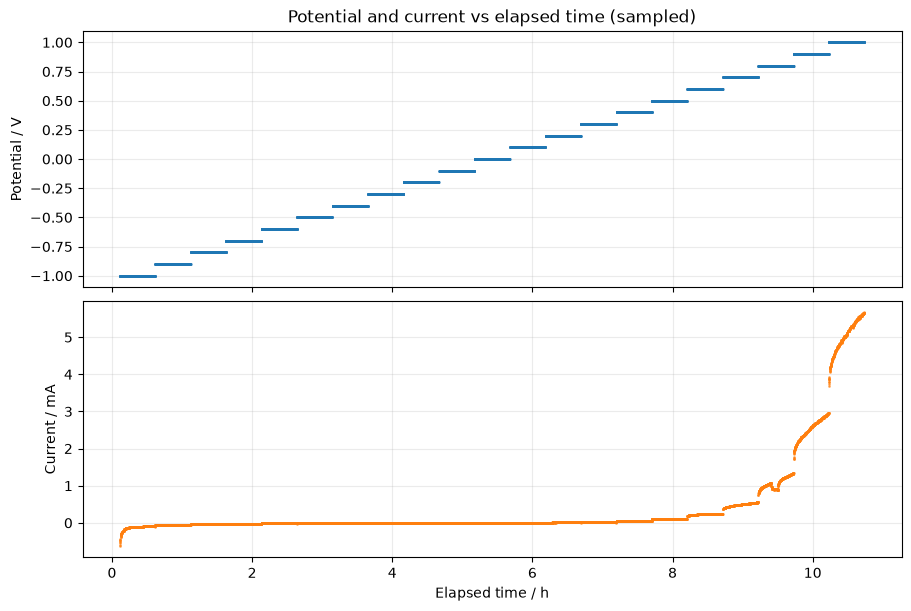

In [3]:
if time_sample.empty:
    print("No valid potential or current time-series data found.")
else:
    fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True, constrained_layout=True)
    t_hours = time_sample["time/s"] / 3600
    axes[0].plot(t_hours, time_sample["<Ewe>/V"], ".", ms=2, alpha=0.6, color="tab:blue")
    axes[0].set_ylabel("Potential / V")
    axes[0].set_title("Potential and current vs elapsed time (sampled)")
    axes[1].plot(t_hours, time_sample["<I>/mA"], ".", ms=2, alpha=0.6, color="tab:orange")
    axes[1].set_ylabel("Current / mA")
    axes[1].set_xlabel("Elapsed time / h")
    for ax in axes:
        ax.grid(alpha=0.25)
    plt.show()
    plt.close(fig)

## Impedance: Nyquist and Bode plots

The Nyquist vertical axis uses the CSV's `-Im(Z)/Ohm` directly: it is **not negated again**. Each point is colored by its recorded potential, not connected to other points, because measurements may belong to different potential steps. The Bode plots use the recorded magnitude and phase, excluding non-finite values (and nonpositive magnitudes for the logarithmic magnitude axis).

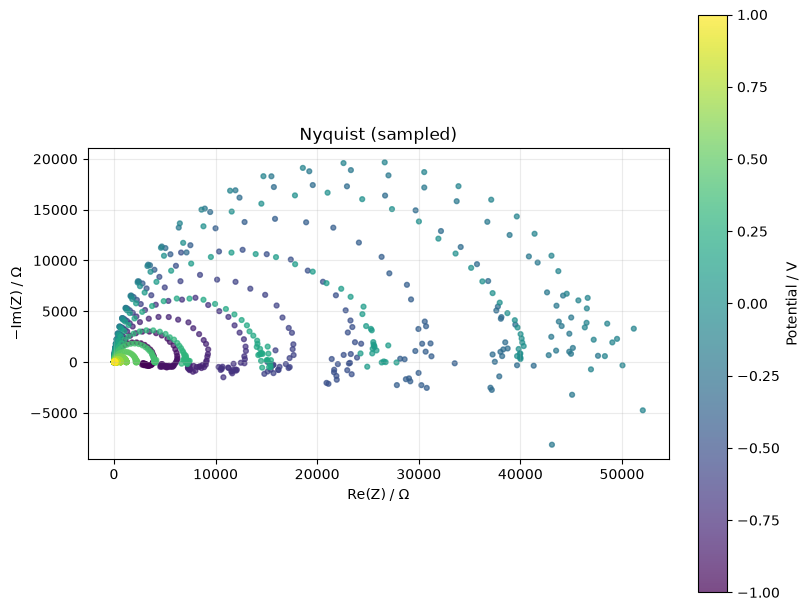

In [7]:
if eis_sample.empty:
    print("No valid positive-frequency impedance data found; Nyquist plot skipped.")
else:
    fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)
    potential = eis_sample["<Ewe>/V"].to_numpy()
    has_potential = np.isfinite(potential).any()
    colors = np.ma.masked_invalid(potential) if has_potential else "tab:blue"

    nyquist = ax.scatter(eis_sample["Re(Z)/Ohm"], eis_sample["-Im(Z)/Ohm"],
                         c=colors, s=12, alpha=0.7,
                         cmap="viridis" if has_potential else None)
    ax.set(xlabel="Re(Z) / Ω", ylabel="−Im(Z) / Ω", title="Nyquist (sampled)")
    ax.set_aspect("equal", adjustable="box")
    if has_potential:
        fig.colorbar(nyquist, ax=ax, label="Potential / V")
    ax.grid(alpha=0.25)
    plt.show()
    plt.close(fig)

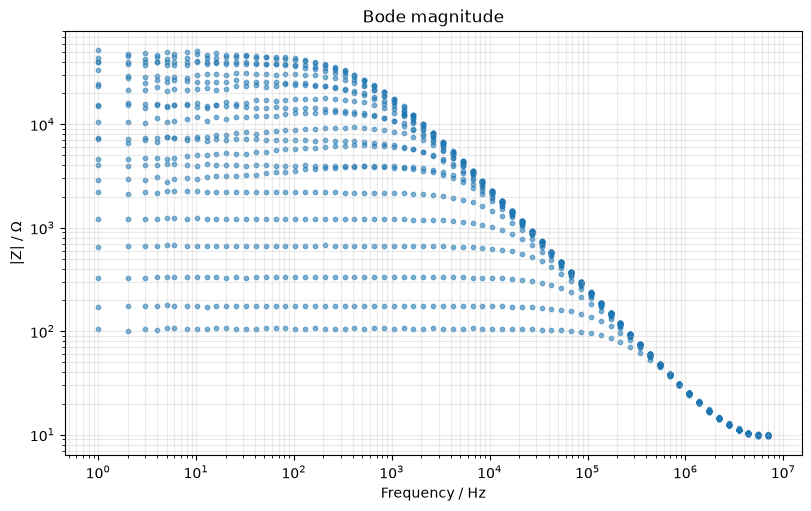

In [8]:
if eis_sample.empty:
    print("No valid positive-frequency impedance data found; Bode magnitude plot skipped.")
else:
    magnitude_mask = np.isfinite(eis_sample["|Z|/Ohm"]) & (eis_sample["|Z|/Ohm"] > 0)
    if not magnitude_mask.any():
        print("No positive finite impedance magnitudes found; Bode magnitude plot skipped.")
    else:
        fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
        ax.scatter(eis_sample.loc[magnitude_mask, "freq/Hz"],
                   eis_sample.loc[magnitude_mask, "|Z|/Ohm"],
                   s=10, alpha=0.55, color="tab:blue")
        ax.set(xscale="log", yscale="log", xlabel="Frequency / Hz",
               ylabel="|Z| / Ω", title="Bode magnitude")
        ax.grid(True, which="both", alpha=0.25)
        plt.show()
        plt.close(fig)

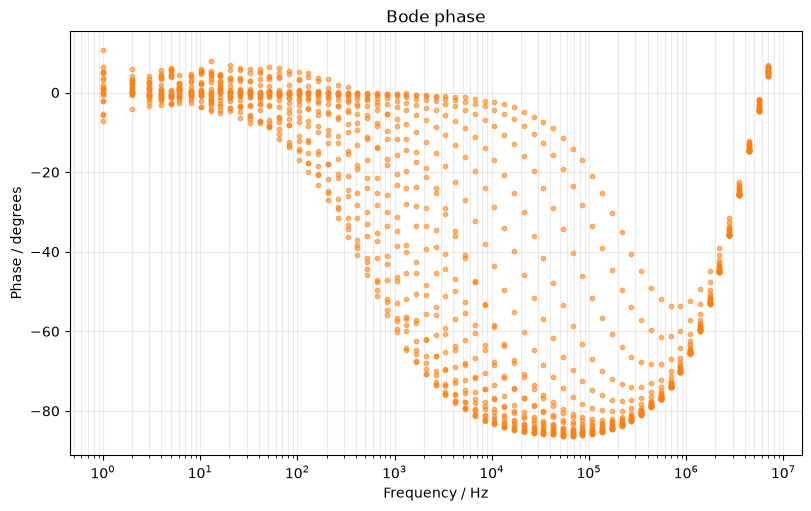

In [9]:
if eis_sample.empty:
    print("No valid positive-frequency impedance data found; Bode phase plot skipped.")
else:
    phase_mask = np.isfinite(eis_sample["Phase(Z)/deg"])
    if not phase_mask.any():
        print("No finite impedance phases found; Bode phase plot skipped.")
    else:
        fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
        ax.scatter(eis_sample.loc[phase_mask, "freq/Hz"],
                   eis_sample.loc[phase_mask, "Phase(Z)/deg"],
                   s=10, alpha=0.55, color="tab:orange")
        ax.set(xscale="log", xlabel="Frequency / Hz", ylabel="Phase / degrees",
               title="Bode phase")
        ax.grid(True, which="both", alpha=0.25)
        plt.show()
        plt.close(fig)

In [10]:
eis_sample

,freq/Hz,Re(Z)/Ohm,-Im(Z)/Ohm,|Z|/Ohm,Phase(Z)/deg,time/s,<Ewe>/V,<I>/mA,cycle number,_row,_priority
0,7.000018e+06,9.878236,-0.730416,9.905203,4.228865,2202.185937,-1.000312,-0.103706,1.0,17881,0.882196
1,5.551811e+06,9.829827,0.769944,9.859935,-4.478681,2202.482920,-1.000294,-0.104290,1.0,17882,0.414035
2,4.403234e+06,9.894883,2.595581,10.229650,-14.698410,2202.779937,-1.000256,-0.103497,1.0,17883,0.612667
3,3.492271e+06,10.044198,4.834177,11.146981,-25.701069,2204.342943,-1.000235,-0.104166,1.0,17884,0.140801
4,2.769782e+06,10.122169,7.317736,12.490299,-35.864727,2204.640920,-1.000316,-0.103661,1.0,17885,0.527020
...,...,...,...,...,...,...,...,...,...,...,...
1381,4.992650e+00,106.277420,-0.986890,106.282010,0.532032,38659.789953,1.000030,5.695576,21.0,375167,0.812930
1382,3.994120e+00,103.893550,-1.305270,103.901750,0.719799,38659.790647,1.000030,5.695576,21.0,375168,0.532577
1383,2.995590e+00,106.174060,1.065117,106.179400,-0.574760,38659.791341,1.000030,5.695576,21.0,375169,0.331712
1384,1.997060e+00,100.719250,-2.004274,100.739190,1.140014,38659.792036,1.000030,5.695576,21.0,375170,0.920952


# Voltage-resolved fitting and Mott–Schottky analysis

**Device:** FTO/SnO₂/BiSI/Au, with Au connected to the working lead and FTO connected to the reference and counter leads. The recorded potential is an Au-versus-FTO device bias. For the Mott–Schottky axis we apply the requested convention $V_{\mathrm{corrected}}=V_{\mathrm{meas}}-0.2\,\mathrm{V}$. This fixed work-function-based shift is an assumption, not an independently validated internal voltage or an electrochemical reference. Other voltage labels in the spectrum audit and fitting plots remain measured bias.

The initial model is $R_s+(R_p\parallel\mathrm{CPE})$. Its effective capacitance is a **model-dependent candidate**, not automatically the BiSI depletion capacitance. A carrier-density estimate is conditional on the circuit, interface, depletion approximation, active area, and selected linear range. No automatic flat-band correction or assignment of carrier type is made. Run the cells in order and review the fit diagnostics before selecting spectra and a regression range.

In [22]:
# Analysis configuration — edit and rerun this cell and subsequent analysis cells.
try:
    from speis_fitting import (
        group_spectra, fit_spectrum, impedance_rcpe, candidate_ranges,
        inverse_capacitance_squared, linear_regression, carrier_density,
    )
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        f"Missing {exc.name!r}. Select the project kernel and install the missing dependency; "
        "speis_fitting.py must also be in the notebook's working directory."
    ) from exc

AREA_CM2 = 0.09       # 3 mm × 3 mm, assuming the full overlap is active
RELATIVE_PERMITTIVITY = 38.0
TEMPERATURE_K = 298.15 # reported for context; no thermal voltage correction applied
FREQ_MIN_HZ = None     # optional explicit fit limits, inclusive
FREQ_MAX_HZ = None
EXCLUDE_INDUCTIVE = True  # Exclude rows where -Im(Z) < 0; record and show them
VOLTAGE_SPREAD_LIMIT_V = 0.01
MAX_RELATIVE_RMSE = 0.10   # QC threshold, not a physical validation
EXPECTED_FREQ_RANGE_HZ = (1.0, 7e6)  # instrument settings; adjust if needed
FREQ_RANGE_TOLERANCE = 0.05
REVIEW_SPECTRUM_ID = 1

print(f"Area: {AREA_CM2:g} cm²; εr: {RELATIVE_PERMITTIVITY:g}; temperature: {TEMPERATURE_K:g} K")
print("Voltage is reported as recorded Au vs FTO; no work-function correction is applied.")
print(f"Exclude points with −Im(Z) < 0 from fitting: {EXCLUDE_INDUCTIVE}")

Area: 0.09 cm²; εr: 38; temperature: 298.15 K
Voltage is reported as recorded Au vs FTO; no work-function correction is applied.
Exclude points with −Im(Z) < 0 from fitting: True


## 1. Recover and audit complete spectra

`eis_sample` is capped for plotting. If its length differs from the total valid-impedance count, the CSV is streamed again to recover every valid positive-frequency row. Sweeps are separated at cycle changes or large frequency resets, rather than grouping measured voltages by exact equality. Review the voltage spreads, frequency limits and flags before accepting any spectrum. The expected frequency range comes from instrument settings and is not proof of data quality.

In [16]:
if len(eis_sample) == valid_eis_rows:
    fit_data = eis_sample.copy()
else:
    parts = []
    row_offset = 0
    for part in pd.read_csv(FILE_PATH, usecols=COLUMNS, encoding="utf-8-sig", chunksize=CHUNK_SIZE):
        part = part.apply(pd.to_numeric, errors="coerce")
        part["_row"] = np.arange(row_offset, row_offset + len(part))
        row_offset += len(part)
        good = (np.isfinite(part["freq/Hz"]) & (part["freq/Hz"] > 0)
                & np.isfinite(part["Re(Z)/Ohm"]) & np.isfinite(part["-Im(Z)/Ohm"]))
        parts.append(part.loc[good])
    fit_data = pd.concat(parts, ignore_index=True)
    if len(fit_data) != valid_eis_rows:
        raise ValueError("CSV impedance row count changed since the plotting data was loaded; rerun the loading cell.")

spectra = group_spectra(
    fit_data, direction="descending", voltage_spread_limit=VOLTAGE_SPREAD_LIMIT_V,
    expected_frequency_range=EXPECTED_FREQ_RANGE_HZ, frequency_tolerance=FREQ_RANGE_TOLERANCE,
)
if not spectra:
    raise ValueError("No valid impedance spectra were found.")
audit = pd.DataFrame([
    {"spectrum_id": s.spectrum_id, "cycle": s.cycle, "n_points": len(s.data),
     "distinct_f": s.n_distinct_frequencies, "voltage_V": s.voltage_v,
     "voltage_spread_V": s.voltage_spread_v, "f_min_Hz": s.frequency_min_hz,
     "f_max_Hz": s.frequency_max_hz, "flags": ", ".join(s.flags) or "none"}
    for s in spectra
])
print(f"{len(fit_data):,} impedance rows assigned to {len(spectra)} contiguous spectra.")
display(audit.head(30))
if len(audit) > 30:
    print(f"Showing 30 of {len(audit)} spectra; inspect the audit variable for the rest.")

1,386 impedance rows assigned to 21 contiguous spectra.


,spectrum_id,cycle,n_points,distinct_f,voltage_V,voltage_spread_V,f_min_Hz,f_max_Hz,flags
0,1,1.0,66,66,-1.000324,0.000111,0.99853,7000018.5,none
1,2,2.0,66,66,-0.900366,0.000135,0.99853,7000018.5,none
2,3,3.0,66,66,-0.800278,0.000104,0.99853,7000018.5,none
3,4,4.0,66,66,-0.700334,0.000123,0.99853,7000018.5,none
4,5,5.0,66,66,-0.600343,0.000109,0.99853,7000018.5,none
5,6,6.0,66,66,-0.500300,0.000126,0.99853,7000018.5,none
6,7,7.0,66,66,-0.400324,0.000129,0.99853,7000018.5,none
7,8,8.0,66,66,-0.300369,0.000115,0.99853,7000018.5,none
8,9,9.0,66,66,-0.200380,0.000118,0.99853,7000018.5,none
9,10,10.0,66,66,-0.100321,0.000144,0.99853,7000018.5,none


## 2. Fit each spectrum and inspect quality

The fit uses $Z=\mathrm{Re}(Z)-j[-\mathrm{Im}(Z)]$ and $Z_{\mathrm{model}}=R_s+[1/R_p+Q(j2\pi f)^\alpha]^{-1}$. Real and imaginary residuals are divided by the measured impedance magnitude, with a small numerical floor. By default, points with $-\mathrm{Im}(Z)<0$ are excluded from fitting, as requested; other frequency limits can be set explicitly. Excluded points are retained for review. Negative $-\mathrm{Im}(Z)$ is an inductive-like response, but its physical origin is not established by its sign alone. The reported RMSE is the RMS complex residual, not a Kramers–Kronig test. Parameter uncertainties are local approximations and are suppressed for bound-limited or ill-conditioned fits.

For this parallel branch only, $C_\mathrm{eff}=Q^{1/\alpha}R_p^{(1-\alpha)/\alpha}$. A good numerical fit does not prove that the branch represents semiconductor depletion.

In [17]:
if FREQ_MIN_HZ is not None and (not np.isfinite(FREQ_MIN_HZ) or FREQ_MIN_HZ <= 0):
    raise ValueError("FREQ_MIN_HZ must be positive or None.")
if FREQ_MAX_HZ is not None and (not np.isfinite(FREQ_MAX_HZ) or FREQ_MAX_HZ <= 0):
    raise ValueError("FREQ_MAX_HZ must be positive or None.")
if FREQ_MIN_HZ is not None and FREQ_MAX_HZ is not None and FREQ_MIN_HZ > FREQ_MAX_HZ:
    raise ValueError("FREQ_MIN_HZ must not exceed FREQ_MAX_HZ.")

fit_results = {}
fit_records = []
for spectrum in spectra:
    f = spectrum.data["freq/Hz"].to_numpy(dtype=float)
    selected = np.ones(len(f), dtype=bool)
    if FREQ_MIN_HZ is not None:
        selected &= f >= FREQ_MIN_HZ
    if FREQ_MAX_HZ is not None:
        selected &= f <= FREQ_MAX_HZ
    if EXCLUDE_INDUCTIVE:
        selected &= spectrum.data["-Im(Z)/Ohm"].to_numpy(dtype=float) >= 0
    result = fit_spectrum(spectrum, mask=selected, max_relative_rmse=MAX_RELATIVE_RMSE)
    fit_results[spectrum.spectrum_id] = result
    params = result.parameters if result.parameters is not None else [np.nan] * 4
    errors = np.sqrt(np.maximum(np.diag(result.covariance), 0)) if result.covariance is not None else [np.nan] * 4
    f_range = result.frequency_range_hz if result.frequency_range_hz is not None else (np.nan, np.nan)
    fit_records.append({
        "spectrum_id": spectrum.spectrum_id, "cycle": spectrum.cycle,
        "voltage_V": spectrum.voltage_v, "voltage_spread_V": spectrum.voltage_spread_v,
        "used": len(result.used_rows), "excluded": len(result.excluded_rows),
        "fit_f_min_Hz": f_range[0], "fit_f_max_Hz": f_range[1],
        "Rs_ohm": params[0], "Rs_std_ohm": errors[0],
        "Rp_ohm": params[1], "Rp_std_ohm": errors[1],
        "Q": params[2], "Q_std": errors[2], "alpha": params[3], "alpha_std": errors[3],
        "Ceff_F": result.capacitance_f, "Ceff_std_F": result.capacitance_std_f,
        "complex_RMSE_ohm": result.raw_rmse_ohm, "relative_RMSE": result.relative_rmse,
        "jac_condition": result.jacobian_condition, "success": result.success,
        "flags": ", ".join(result.flags) or "none",
    })
fit_table = pd.DataFrame(fit_records)
print(f"Fits converged: {fit_table['success'].sum()} / {len(fit_table)}; inspect flags and residuals before use.")
display(fit_table.head(30))
if len(fit_table) > 30:
    print(f"Showing 30 of {len(fit_table)} fits; inspect fit_table for the rest.")

Fits converged: 21 / 21; inspect flags and residuals before use.


,spectrum_id,cycle,voltage_V,voltage_spread_V,used,excluded,fit_f_min_Hz,fit_f_max_Hz,Rs_ohm,Rs_std_ohm,...,Q_std,alpha,alpha_std,Ceff_F,Ceff_std_F,complex_RMSE_ohm,relative_RMSE,jac_condition,success,flags
0,1,1.0,-1.000324,0.000111,42,24,414.33722,5551811.0,10.088675,NaN,...,NaN,1.000000,NaN,6.562871e-09,NaN,75.086684,0.087394,82.647717,True,"user_excluded_points, parameter_at_bound, unce..."
1,2,2.0,-0.900366,0.000135,44,22,260.58405,5551811.0,10.154228,NaN,...,NaN,1.000000,NaN,6.564009e-09,NaN,117.296804,0.085655,76.292993,True,"user_excluded_points, parameter_at_bound, unce..."
2,3,3.0,-0.800278,0.000104,46,20,163.89862,5551811.0,10.129532,NaN,...,NaN,1.000000,NaN,6.574248e-09,NaN,189.524311,0.087371,71.127623,True,"user_excluded_points, parameter_at_bound, unce..."
3,4,4.0,-0.700334,0.000123,47,19,129.95824,5551811.0,10.099088,0.292930,...,4.018409e-10,0.995851,0.004390,6.711460e-09,1.291168e-10,257.147785,0.086417,67.218276,True,user_excluded_points
4,5,5.0,-0.600343,0.000109,51,15,0.99853,5551811.0,10.035048,0.301647,...,4.001785e-10,0.994332,0.004317,6.777756e-09,1.335569e-10,554.190851,0.089716,63.788838,True,user_excluded_points
5,6,6.0,-0.500300,0.000126,54,12,0.99853,5551811.0,9.969759,0.301310,...,3.990452e-10,0.989740,0.004078,6.958968e-09,1.358772e-10,720.731428,0.089766,60.400085,True,user_excluded_points
6,7,7.0,-0.400324,0.000129,57,9,5.99118,5551811.0,9.956024,0.290210,...,3.701149e-10,0.988538,0.003764,6.998890e-09,1.302194e-10,783.856566,0.086626,57.949617,True,user_excluded_points
7,8,8.0,-0.300369,0.000115,60,6,0.99853,5551811.0,9.879572,0.309626,...,4.002176e-10,0.983785,0.003843,7.210133e-09,1.420674e-10,1098.107621,0.092476,55.600079,True,user_excluded_points
8,9,9.0,-0.200380,0.000118,63,3,2.99559,5551811.0,9.781585,0.310736,...,4.076355e-10,0.980783,0.003772,7.353264e-09,1.455397e-10,1543.869304,0.093341,54.218742,True,user_excluded_points
9,10,10.0,-0.100321,0.000144,62,4,1.99706,5551811.0,9.751785,0.337307,...,4.663144e-10,0.975658,0.004019,7.606705e-09,1.633481e-10,1979.165754,0.100684,53.646379,True,"user_excluded_points, poor_relative_fit"


### Review one spectrum

Change `REVIEW_SPECTRUM_ID` in the configuration cell and rerun it and the subsequent cells to inspect another fit. The residual components below are normalized by measured $|Z|$. Inspect representative low, middle, and high voltages; a single R–CPE model may be inadequate, particularly where inductive features or multiple arcs appear.

Spectrum 1, bias -1.0003 V, flags: user_excluded_points, parameter_at_bound, uncertainty_unavailable


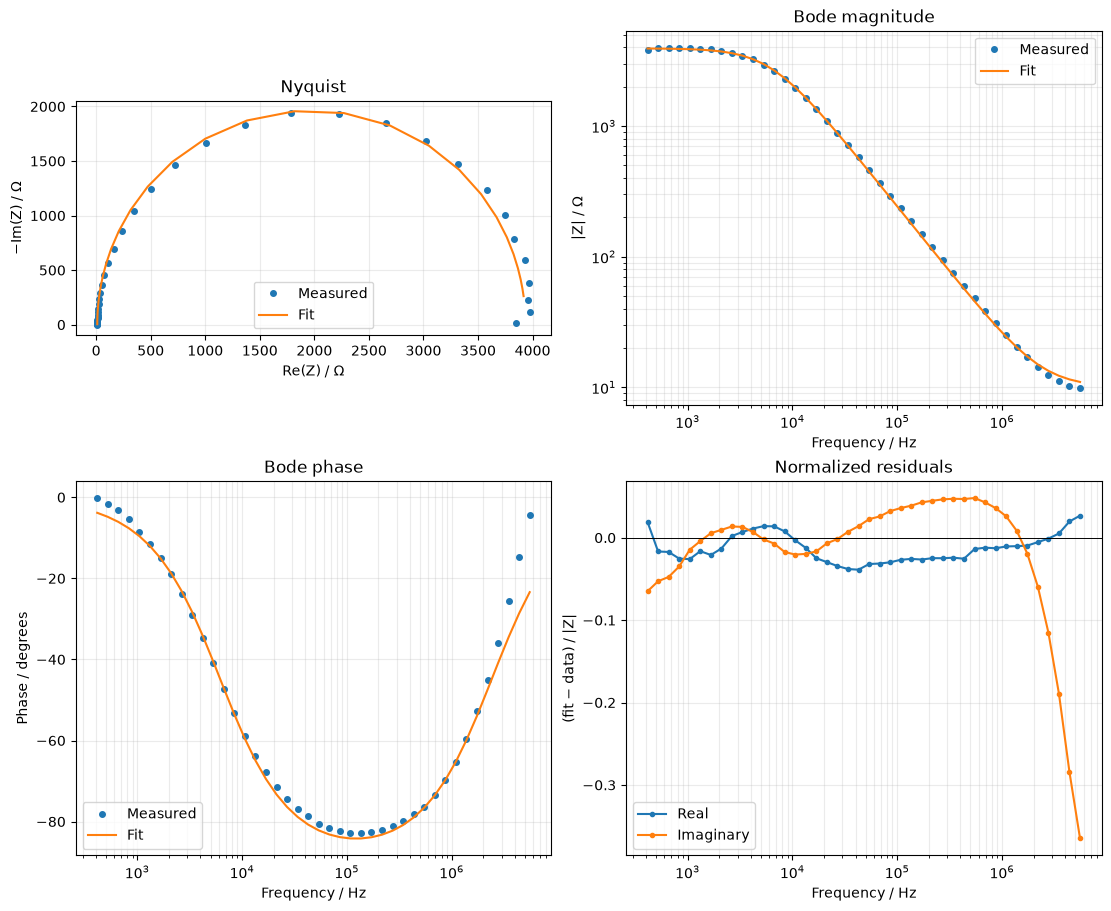

In [18]:
review = next((s for s in spectra if s.spectrum_id == REVIEW_SPECTRUM_ID), None)
if review is None:
    print(f"Spectrum {REVIEW_SPECTRUM_ID} does not exist.")
else:
    result = fit_results[review.spectrum_id]
    print(f"Spectrum {review.spectrum_id}, bias {review.voltage_v:.4f} V, flags: {', '.join(result.flags) or 'none'}")
    if not result.success:
        print(f"Fit unavailable: {result.message}")
    else:
        data = review.data[review.data["_row"].isin(result.used_rows)].sort_values("freq/Hz")
        f = data["freq/Hz"].to_numpy(dtype=float)
        z = data["Re(Z)/Ohm"].to_numpy(dtype=float) - 1j * data["-Im(Z)/Ohm"].to_numpy(dtype=float)
        z_fit = impedance_rcpe(f, *result.parameters)
        weight = np.maximum(np.abs(z), result.modulus_floor_ohm)
        residual = (z_fit - z) / weight
        fig, axes = plt.subplots(2, 2, figsize=(11, 9), constrained_layout=True)
        axes[0, 0].plot(z.real, -z.imag, "o", ms=4, label="Measured")
        axes[0, 0].plot(z_fit.real, -z_fit.imag, "-", label="Fit")
        axes[0, 0].set(xlabel="Re(Z) / Ω", ylabel="−Im(Z) / Ω", title="Nyquist")
        axes[0, 0].set_aspect("equal", adjustable="box")
        axes[0, 1].loglog(f, np.abs(z), "o", ms=4, label="Measured")
        axes[0, 1].loglog(f, np.abs(z_fit), "-", label="Fit")
        axes[0, 1].set(xlabel="Frequency / Hz", ylabel="|Z| / Ω", title="Bode magnitude")
        axes[1, 0].semilogx(f, np.angle(z, deg=True), "o", ms=4, label="Measured")
        axes[1, 0].semilogx(f, np.angle(z_fit, deg=True), "-", label="Fit")
        axes[1, 0].set(xlabel="Frequency / Hz", ylabel="Phase / degrees", title="Bode phase")
        axes[1, 1].semilogx(f, residual.real, ".-", label="Real")
        axes[1, 1].semilogx(f, residual.imag, ".-", label="Imaginary")
        axes[1, 1].axhline(0, color="black", linewidth=0.7)
        axes[1, 1].set(xlabel="Frequency / Hz", ylabel="(fit − data) / |Z|", title="Normalized residuals")
        for ax in axes.flat:
            ax.grid(True, which="both", alpha=0.25)
            ax.legend()
        plt.show()
        plt.close(fig)

### All fitted spectra

Every spectrum is shown below in acquisition order, three spectra per figure. Blue points are used in the fit; red crosses are excluded by the configured sign or frequency filters. The orange line is the model prediction across the retained frequency range; it interpolates across any excluded gaps and does not mean those points were fitted. Nyquist axes use equal scaling. Relative RMSE and fit flags appear above each row; convergence alone does not establish a good fit. Use the individual review above for residuals.

Spectrum  1 (-1.0003 V): 42 used, 24 excluded; flags: user_excluded_points, parameter_at_bound, uncertainty_unavailable
Spectrum  2 (-0.9004 V): 44 used, 22 excluded; flags: user_excluded_points, parameter_at_bound, uncertainty_unavailable
Spectrum  3 (-0.8003 V): 46 used, 20 excluded; flags: user_excluded_points, parameter_at_bound, uncertainty_unavailable


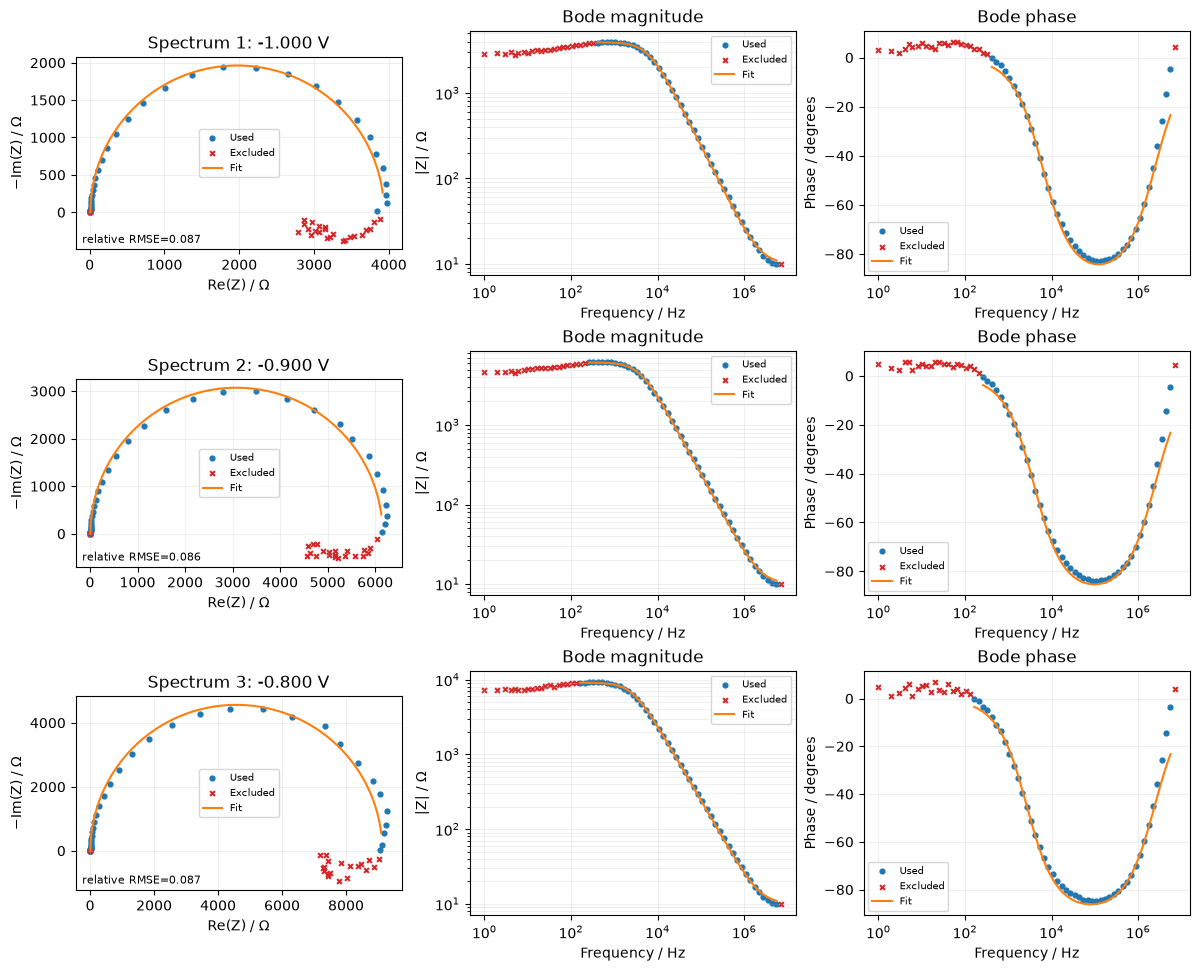

Spectrum  4 (-0.7003 V): 47 used, 19 excluded; flags: user_excluded_points
Spectrum  5 (-0.6003 V): 51 used, 15 excluded; flags: user_excluded_points
Spectrum  6 (-0.5003 V): 54 used, 12 excluded; flags: user_excluded_points


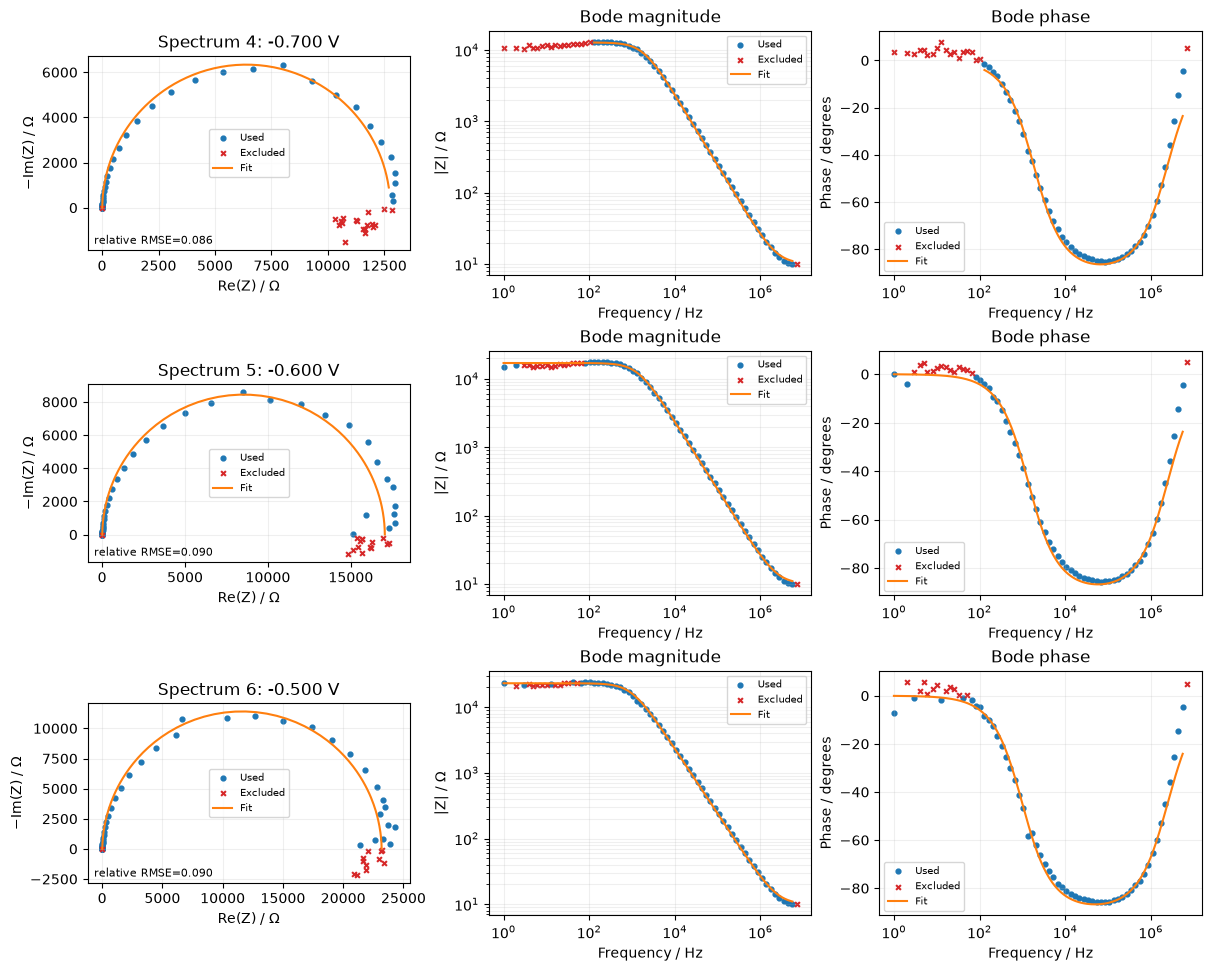

Spectrum  7 (-0.4003 V): 57 used, 9 excluded; flags: user_excluded_points
Spectrum  8 (-0.3004 V): 60 used, 6 excluded; flags: user_excluded_points
Spectrum  9 (-0.2004 V): 63 used, 3 excluded; flags: user_excluded_points


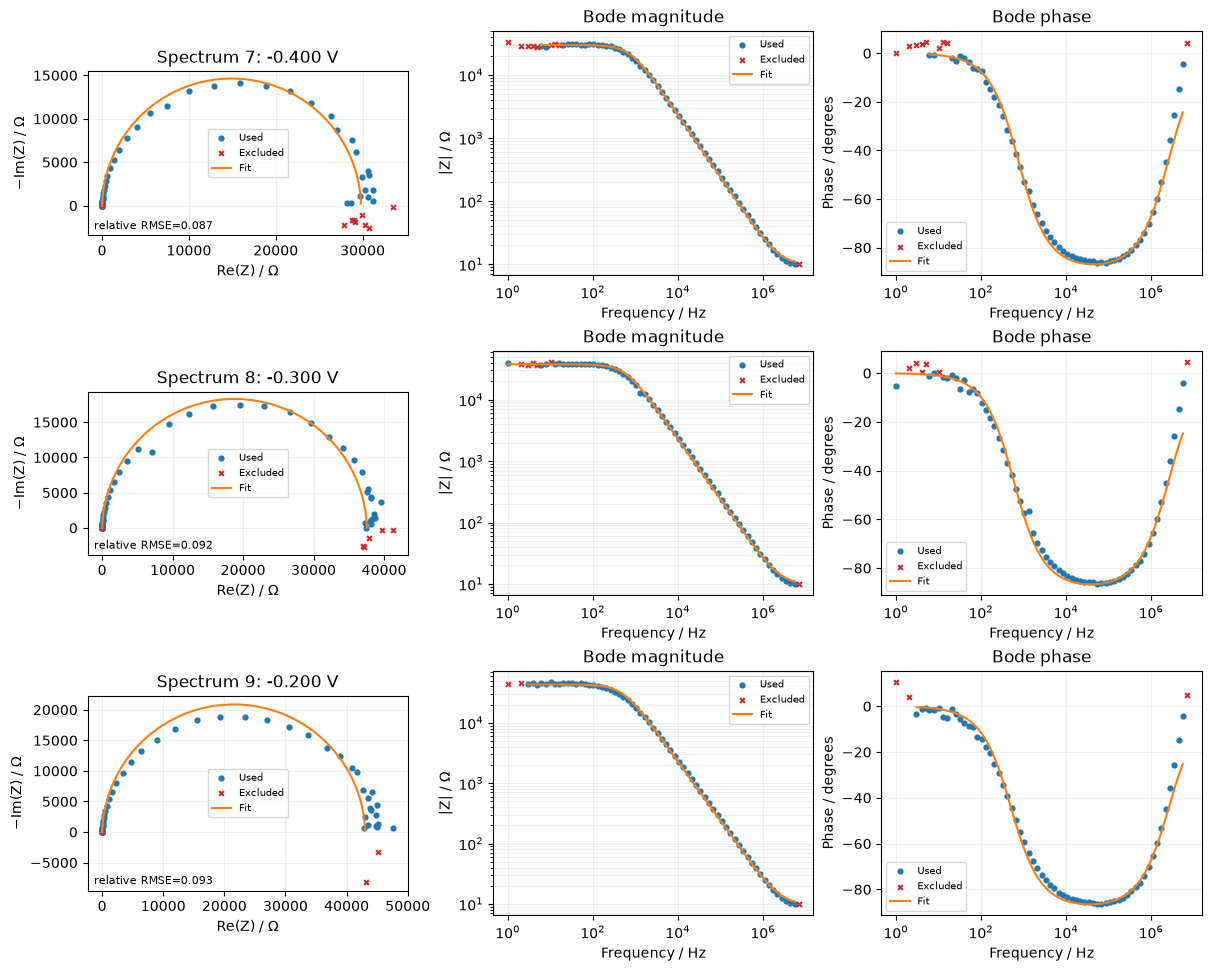

Spectrum 10 (-0.1003 V): 62 used, 4 excluded; flags: user_excluded_points, poor_relative_fit
Spectrum 11 (-0.0004 V): 65 used, 1 excluded; flags: user_excluded_points
Spectrum 12 (+0.0996 V): 61 used, 5 excluded; flags: user_excluded_points


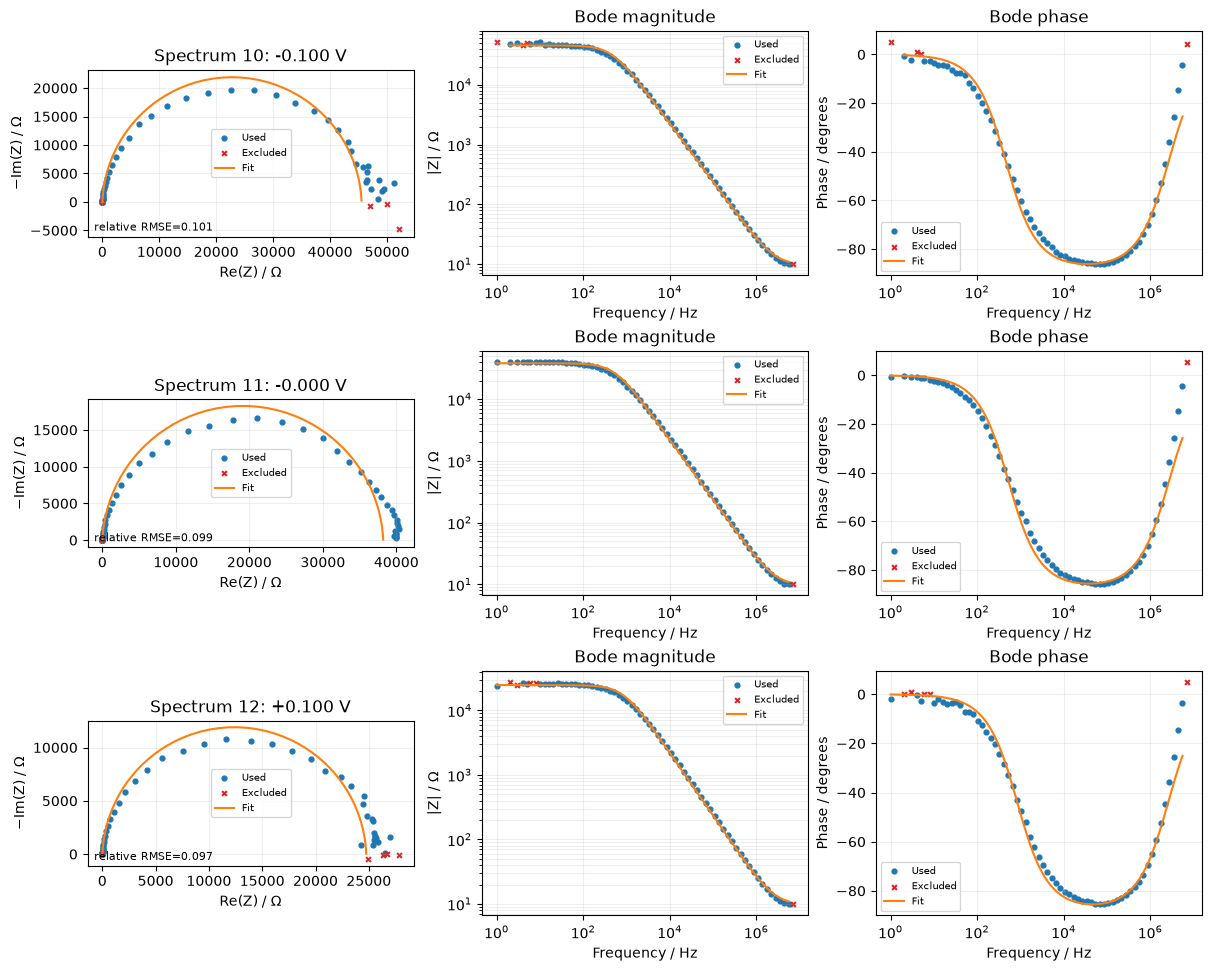

Spectrum 13 (+0.1996 V): 61 used, 5 excluded; flags: user_excluded_points
Spectrum 14 (+0.3001 V): 61 used, 5 excluded; flags: user_excluded_points
Spectrum 15 (+0.4001 V): 64 used, 2 excluded; flags: user_excluded_points


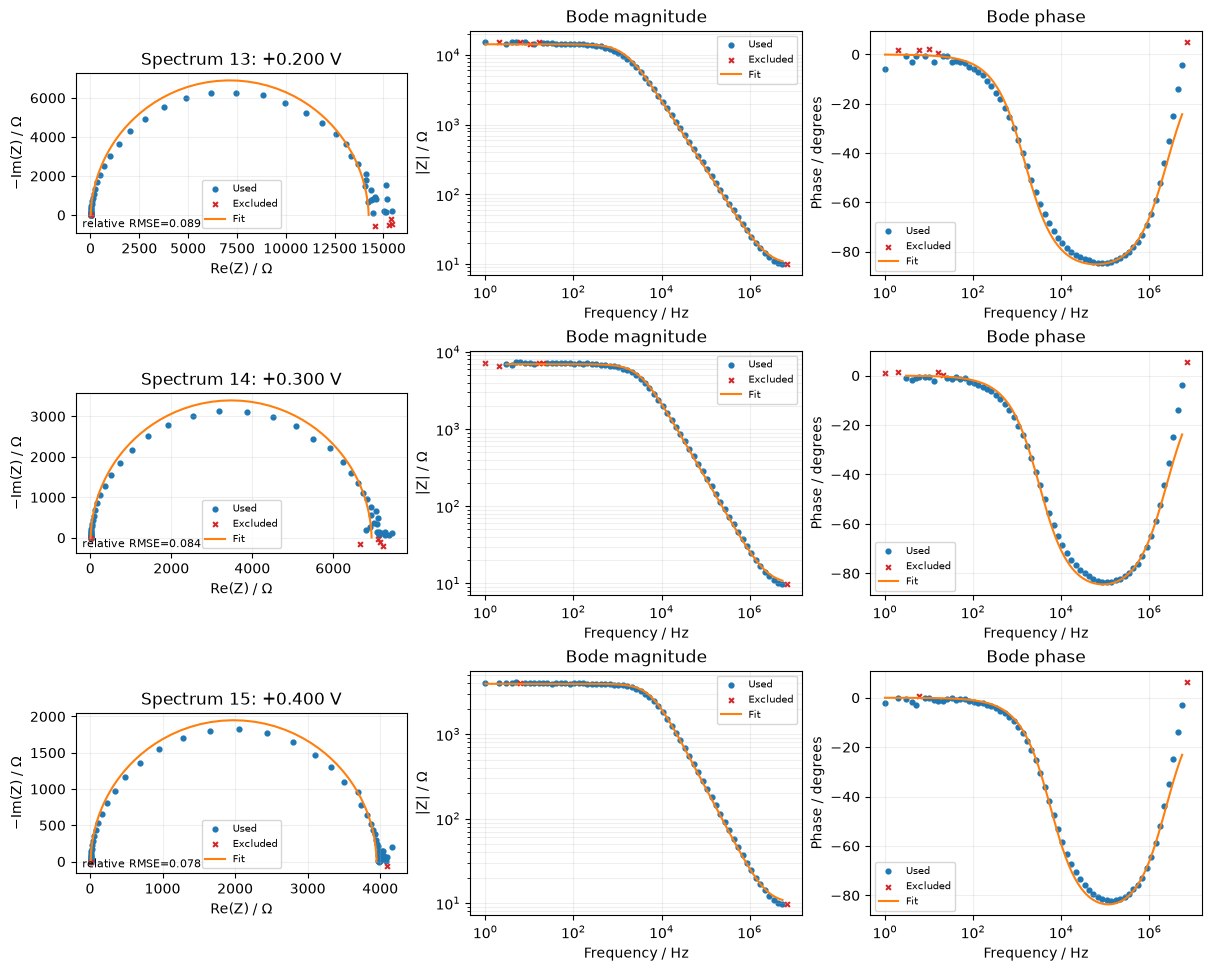

Spectrum 16 (+0.5001 V): 62 used, 4 excluded; flags: user_excluded_points
Spectrum 17 (+0.6001 V): 62 used, 4 excluded; flags: user_excluded_points, parameter_at_bound, uncertainty_unavailable
Spectrum 18 (+0.7001 V): 55 used, 11 excluded; flags: user_excluded_points, parameter_at_bound, uncertainty_unavailable


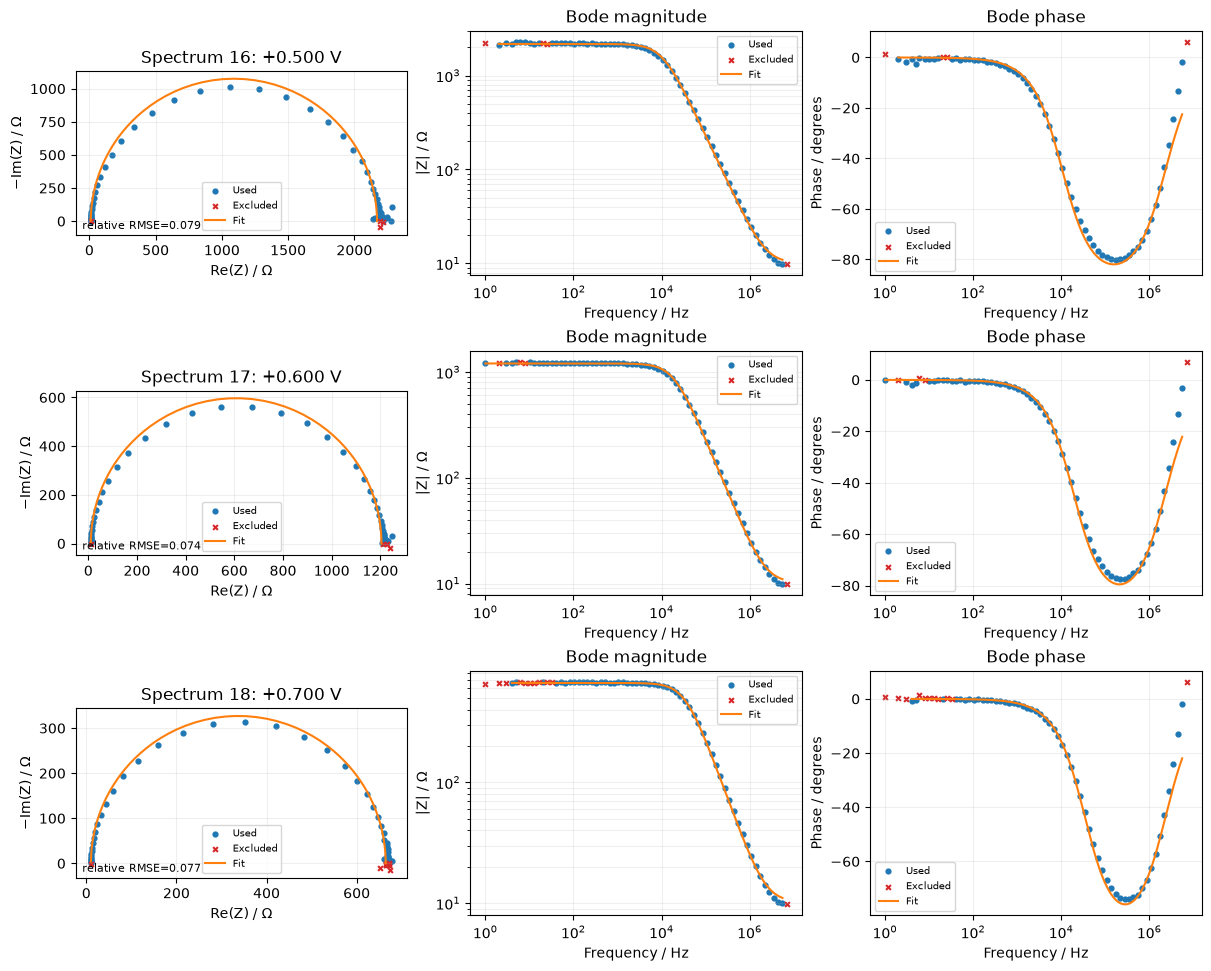

Spectrum 19 (+0.8000 V): 52 used, 14 excluded; flags: user_excluded_points, parameter_at_bound, uncertainty_unavailable
Spectrum 20 (+0.9001 V): 49 used, 17 excluded; flags: user_excluded_points, parameter_at_bound, uncertainty_unavailable
Spectrum 21 (+1.0001 V): 49 used, 17 excluded; flags: user_excluded_points, parameter_at_bound, uncertainty_unavailable


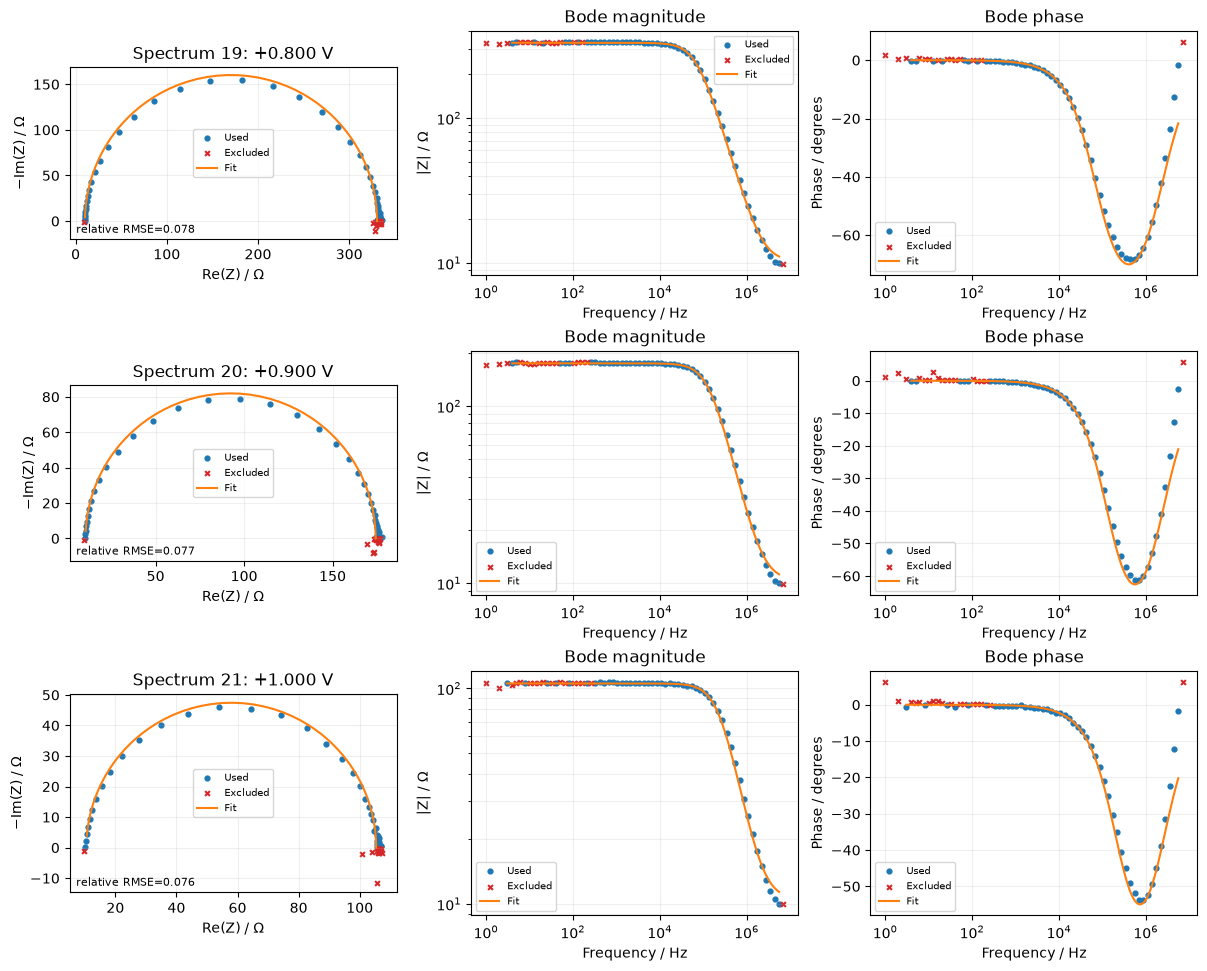

In [19]:
# Show all fits in compact pages to avoid creating 21 full-size figures.
SPECTRA_PER_PAGE = 3
for page_start in range(0, len(spectra), SPECTRA_PER_PAGE):
    page = spectra[page_start:page_start + SPECTRA_PER_PAGE]
    fig, axes = plt.subplots(len(page), 3, figsize=(12, 3.2 * len(page)),
                             squeeze=False, constrained_layout=True)
    for row, spectrum in enumerate(page):
        result = fit_results[spectrum.spectrum_id]
        included = spectrum.data[spectrum.data["_row"].isin(result.used_rows)].sort_values("freq/Hz")
        excluded = spectrum.data[spectrum.data["_row"].isin(result.excluded_rows)].sort_values("freq/Hz")
        ax_n, ax_m, ax_p = axes[row]
        for data, marker, color, label in (
            (included, "o", "tab:blue", "Used"),
            (excluded, "x", "tab:red", "Excluded"),
        ):
            if data.empty:
                continue
            f_points = data["freq/Hz"].to_numpy(dtype=float)
            z_points = data["Re(Z)/Ohm"].to_numpy(dtype=float) - 1j * data["-Im(Z)/Ohm"].to_numpy(dtype=float)
            ax_n.scatter(z_points.real, -z_points.imag, marker=marker, s=12, color=color, label=label)
            ax_m.scatter(f_points, np.abs(z_points), marker=marker, s=12, color=color, label=label)
            ax_p.scatter(f_points, np.angle(z_points, deg=True), marker=marker, s=12, color=color, label=label)
        if result.success and not included.empty:
            fit_f = np.geomspace(included["freq/Hz"].min(), included["freq/Hz"].max(), 200)
            fit_z = impedance_rcpe(fit_f, *result.parameters)
            ax_n.plot(fit_z.real, -fit_z.imag, color="tab:orange", label="Fit")
            ax_m.plot(fit_f, np.abs(fit_z), color="tab:orange", label="Fit")
            ax_p.plot(fit_f, np.angle(fit_z, deg=True), color="tab:orange", label="Fit")
            quality = f"relative RMSE={result.relative_rmse:.3f}"
        else:
            quality = "fit failed: " + result.message
        ax_n.set(xlabel="Re(Z) / Ω", ylabel="−Im(Z) / Ω", title=f"Spectrum {spectrum.spectrum_id}: {spectrum.voltage_v:+.3f} V")
        ax_n.set_aspect("equal", adjustable="box")
        ax_m.set(xscale="log", yscale="log", xlabel="Frequency / Hz", ylabel="|Z| / Ω", title="Bode magnitude")
        ax_p.set(xscale="log", xlabel="Frequency / Hz", ylabel="Phase / degrees", title="Bode phase")
        ax_n.text(0.02, 0.02, quality, transform=ax_n.transAxes, fontsize=8, va="bottom")
        flags = ", ".join(result.flags) if result.flags else "none"
        print(f"Spectrum {spectrum.spectrum_id:2d} ({spectrum.voltage_v:+.4f} V): "
              f"{len(result.used_rows)} used, {len(result.excluded_rows)} excluded; flags: {flags}")
        for ax in (ax_n, ax_m, ax_p):
            ax.grid(True, which="both", alpha=0.2)
            ax.legend(fontsize=7)
    plt.show()
    plt.close(fig)

## 3. Mott–Schottky candidates

The plot shows all converged positive $C_\mathrm{eff}$ estimates, including flagged fits for inspection. Candidate windows exclude fits flagged for high residual, parameter bounds, ill-conditioning, incomplete sweeps, voltage drift, frequency reversal, invalid input or repeated bias. These are screening rules—not proof of physical validity. Candidate windows must contain at least four distinct voltages and span `MIN_WINDOW_SPAN_V`. Ranked $R^2$ can favor short windows; review fit residuals, window width and physical meaning rather than accepting the highest score automatically.

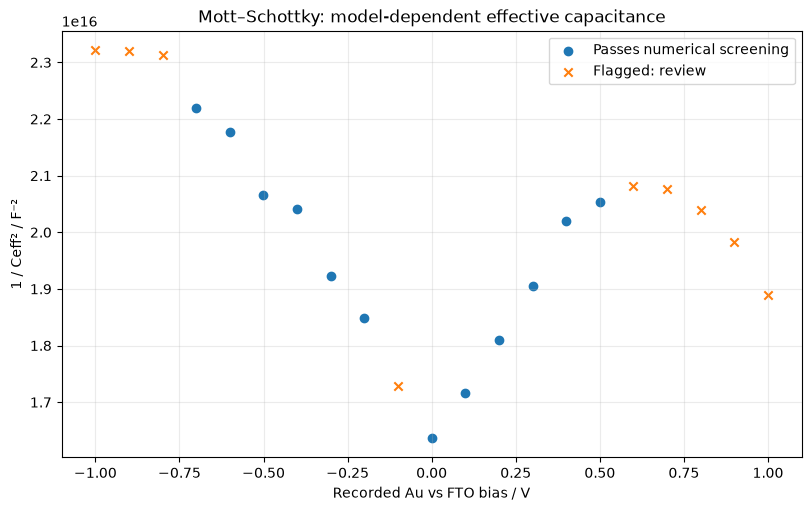

10 exploratory candidate windows; the first 10 are shown. No range is selected automatically.


,n_points,voltage_min_v,voltage_max_v,span_v,slope,intercept,r_squared,rmse,flags
candidate,,,,,,,,,
0,4,-0.000373,0.300076,0.300449,8.994595e+15,1.632187e+16,0.998183,4.296863e+13,"(intercept_extrapolated,)"
1,4,0.099596,0.400060,0.300465,1.004533e+16,1.611570e+16,0.997767,5.323137e+13,"(intercept_extrapolated,)"
2,5,-0.000373,0.400060,0.400433,9.538907e+15,1.626762e+16,0.995950,8.613832e+13,"(intercept_extrapolated,)"
3,6,-0.000373,0.500113,0.500486,8.810036e+15,1.636458e+16,0.988283,1.640306e+14,"(intercept_extrapolated,)"
4,5,0.099596,0.500113,0.400517,8.823021e+15,1.635982e+16,0.979746,1.796646e+14,"(intercept_extrapolated,)"
5,6,-0.700334,-0.200380,0.499954,-7.533261e+15,1.706807e+16,0.979033,1.882577e+14,"(intercept_extrapolated,)"
6,5,-0.600343,-0.200380,0.399963,-7.962966e+15,1.692468e+16,0.973946,1.841626e+14,"(intercept_extrapolated,)"
7,5,-0.700334,-0.300369,0.399965,-7.283665e+15,1.720959e+16,0.963998,1.990524e+14,"(intercept_extrapolated,)"
8,4,0.199648,0.500113,0.300465,8.404715e+15,1.652716e+16,0.960969,1.896397e+14,"(intercept_extrapolated,)"


In [20]:
MIN_WINDOW_SPAN_V = 0.3
MIN_WINDOW_POINTS = 4
BLOCKING_FLAGS = {
    "invalid_impedance_or_frequency", "invalid_voltage", "voltage_spread",
    "too_few_distinct_frequencies", "frequency_reversal", "incomplete_sweep",
    "missing_cycle", "possible_repeated_bias", "poor_relative_fit",
    "parameter_at_bound", "ill_conditioned", "fit_failed",
}
valid_results = fit_table.loc[
    fit_table["success"] & np.isfinite(fit_table["voltage_V"])
    & np.isfinite(fit_table["Ceff_F"]) & (fit_table["Ceff_F"] > 0)
].copy()
valid_results["eligible"] = valid_results["spectrum_id"].map(
    lambda sid: not bool(BLOCKING_FLAGS.intersection(fit_results[sid].flags))
)
if valid_results.empty:
    print("No converged fits with finite voltage and positive effective capacitance.")
else:
    valid_results["inverse_C2_F-2"] = inverse_capacitance_squared(valid_results["Ceff_F"].to_numpy())[0]
    fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
    for eligible, marker, label in [(True, "o", "Passes numerical screening"), (False, "x", "Flagged: review")]:
        part = valid_results.loc[valid_results["eligible"] == eligible]
        if not part.empty:
            ax.scatter(part["voltage_V"], part["inverse_C2_F-2"], marker=marker, label=label)
    ax.set(xlabel="Recorded Au vs FTO bias / V", ylabel="1 / Ceff² / F⁻²",
           title="Mott–Schottky: model-dependent effective capacitance")
    ax.grid(alpha=0.25)
    ax.legend()
    plt.show()
    plt.close(fig)

eligible_ms = valid_results.loc[valid_results["eligible"]].sort_values("voltage_V").reset_index(drop=True)
windows = candidate_ranges(eligible_ms["voltage_V"].to_numpy(), eligible_ms["Ceff_F"].to_numpy(),
                           min_span_v=MIN_WINDOW_SPAN_V, min_points=MIN_WINDOW_POINTS)
if fit_table["voltage_V"].isna().any():
    print("Warning: some spectra have no valid bias; their position in candidate windows cannot be checked.")
if not windows.empty:
    # Do not bridge over excluded or failed spectra within a proposed bias range.
    def contains_only_selected_spectra(window):
        in_range = fit_table.loc[
            fit_table["voltage_V"].between(window["voltage_min_v"], window["voltage_max_v"]), "spectrum_id"
        ]
        selected_ids = eligible_ms.iloc[list(window["indices"])]["spectrum_id"]
        return set(in_range) == set(selected_ids)
    windows = windows.loc[windows.apply(contains_only_selected_spectra, axis=1)]
if windows.empty:
    print(f"No candidate windows: {len(eligible_ms)} spectra pass screening. Review fits, grouping and model before proceeding.")
else:
    windows = windows.sort_values(["r_squared", "span_v"], ascending=[False, False], na_position="last").reset_index(drop=True)
    windows.index.name = "candidate"
    print(f"{len(windows)} exploratory candidate windows; the first 10 are shown. No range is selected automatically.")
    display(windows.drop(columns="indices").head(10))

## 4. Confirm a linear range

After reviewing the spectrum fits, enter a candidate number and explicitly set `CONFIRM_MODEL_AND_RANGE = True` to calculate the intercept and conditional density. The regression is **unweighted**; uncertainty reflects residual scatter only and excludes uncertainty in electrode area, permittivity, model selection, and range selection. The x-intercept is not automatically a flat-band voltage. Re-run the candidate cell whenever fit configuration or data changes.

In [21]:
# Set these only after reviewing the individual spectra, circuit and candidate ranges.
SELECTED_CANDIDATE = None  # e.g. 0 for the first row in the candidate table
CONFIRM_MODEL_AND_RANGE = False

ms_regression = None
ms_density = None
if not CONFIRM_MODEL_AND_RANGE or SELECTED_CANDIDATE is None:
    print("No final Mott–Schottky estimate: review the fits and explicitly confirm a candidate range.")
elif SELECTED_CANDIDATE not in windows.index:
    print("Selected candidate does not exist; review the candidate table.")
else:
    chosen = windows.loc[SELECTED_CANDIDATE]
    chosen_data = eligible_ms.iloc[list(chosen["indices"])].copy()
    v = chosen_data["voltage_V"].to_numpy(dtype=float)
    inv_c2 = chosen_data["inverse_C2_F-2"].to_numpy(dtype=float)
    ms_regression = linear_regression(v, inv_c2)
    if ms_regression.x_intercept_v is None:
        print("Slope is too small or the intercept is unavailable; density not calculated.")
    else:
        ms_density = carrier_density(ms_regression, area_m2=AREA_CM2 * 1e-4,
                                     relative_permittivity=RELATIVE_PERMITTIVITY,
                                     confirmed=CONFIRM_MODEL_AND_RANGE)
        print(f"Selected spectra: {chosen_data['spectrum_id'].tolist()}")
        print(f"Unweighted slope: {ms_regression.slope:.5e} ± {np.sqrt(ms_regression.covariance[0, 0]):.2e} F⁻² V⁻¹")
        print(f"x-intercept: {ms_regression.x_intercept_v:.5g} ± {ms_regression.x_intercept_std_v:.2g} V (recorded bias)")
        print(f"Conditional effective carrier concentration: {ms_density['density_cm3']:.4e} ± {ms_density['std_cm3']:.2e} cm⁻³")
        print(f"Fit range: {v.min():.4f} to {v.max():.4f} V; R² = {ms_regression.r_squared:.4f}; flags: {', '.join(ms_regression.flags) or 'none'}")
        print("Uncertainty is slope-only; no flat-band or contact-work-function correction has been applied.")
        fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
        ax.scatter(valid_results["voltage_V"], valid_results["inverse_C2_F-2"], alpha=0.45, label="All valid capacitances")
        ax.scatter(v, inv_c2, label="Selected for regression")
        line_v = np.linspace(v.min(), v.max(), 200)
        ax.plot(line_v, ms_regression.slope * line_v + ms_regression.intercept, label="Unweighted linear fit")
        ax.set(xlabel="Recorded Au vs FTO bias / V", ylabel="1 / Ceff² / F⁻²", title="Selected Mott–Schottky range")
        ax.grid(alpha=0.25)
        ax.legend()
        plt.show()
        plt.close(fig)

No final Mott–Schottky estimate: review the fits and explicitly confirm a candidate range.


## 5. Optional export

Set `EXPORT_RESULTS` to `True` only when ready. The export contains compact fit and audit tables and the current analysis settings; the original CSV is never modified. The optional JSON is descriptive and includes the final estimate only if it was explicitly confirmed in the previous cell.

In [12]:
import json

EXPORT_RESULTS = False
OUTPUT_DIR = Path("speis_results")
if EXPORT_RESULTS:
    OUTPUT_DIR.mkdir(exist_ok=True)
    audit.to_csv(OUTPUT_DIR / "spectrum_audit.csv", index=False)
    fit_table.to_csv(OUTPUT_DIR / "circuit_fits.csv", index=False)
    settings = {
        "source_csv": str(FILE_PATH), "circuit": "Rs + (Rp || CPE)",
        "weighting": "complex residual / measured |Z| (with numerical floor)",
        "area_cm2": AREA_CM2, "relative_permittivity": RELATIVE_PERMITTIVITY,
        "temperature_K": TEMPERATURE_K, "f_min_hz": FREQ_MIN_HZ, "f_max_hz": FREQ_MAX_HZ,
        "exclude_inductive": EXCLUDE_INDUCTIVE, "voltage_spread_limit_v": VOLTAGE_SPREAD_LIMIT_V,
        "max_relative_rmse": MAX_RELATIVE_RMSE, "expected_frequency_range_hz": EXPECTED_FREQ_RANGE_HZ,
        "frequency_range_tolerance": FREQ_RANGE_TOLERANCE, "blocking_flags": sorted(BLOCKING_FLAGS),
        "candidate_min_span_v": MIN_WINDOW_SPAN_V, "candidate_min_points": MIN_WINDOW_POINTS,
        "selected_candidate": SELECTED_CANDIDATE if ms_regression is not None else None,
        "model_and_range_confirmed": bool(CONFIRM_MODEL_AND_RANGE and ms_density is not None),
        "result": None,
    }
    if ms_regression is not None and ms_density is not None:
        settings["result"] = {
            "spectrum_ids": [int(value) for value in chosen_data["spectrum_id"]],
            "slope_F_minus2_per_V": float(ms_regression.slope),
            "slope_std_F_minus2_per_V": float(np.sqrt(ms_regression.covariance[0, 0])),
            "intercept_F_minus2": float(ms_regression.intercept),
            "x_intercept_V": float(ms_regression.x_intercept_v),
            "x_intercept_std_V": float(ms_regression.x_intercept_std_v),
            "range_V": list(ms_regression.voltage_range_v), "flags": ms_regression.flags,
            "density_cm_minus3": float(ms_density["density_cm3"]),
            "density_std_cm_minus3": float(ms_density["std_cm3"]),
        }
    (OUTPUT_DIR / "analysis_settings.json").write_text(json.dumps(settings, indent=2, allow_nan=False), encoding="utf-8")
    print(f"Exported compact tables and settings to {OUTPUT_DIR.resolve()}")
else:
    print("Export disabled; no files written.")

Export disabled; no files written.
